# Projet Leyanda

## Contexte

Nous cherchons à faire du captionning c'est à dire mettre une legende sur une image. L'objectif est de décrire les aliments d'un plat en ajoutant les noms des aliments.

# Etape 0 : Créer un environnement virtuel et installer toutes les dépendances

Pour faire ceci on va utiliser le package venv de python de base puis installer le package ipykernel afin d'utiliser le venv depuis le notebook. Une fois que le code si dessous est effectué, il reste plus qu'à selectionner le Kernel datascienceENV

In [ ]:
python -m venv .venv
#source .venv/bin/activate sur les systems Linux ou Mac
.\.venv\Scripts\Activate.ps1
pip install ipykernel
pip install -r requirements.txt
python -m ipykernel install --user --name=".venv" --display-name="datascienceENV"

# Etape 1 : Télécharger plusieurs dataset et le nettoyer puis le normaliser

On nous a fourni plusieurs datasets qui sont des répartits par dossier. Tout d'abord nous allons vérifier le format des images

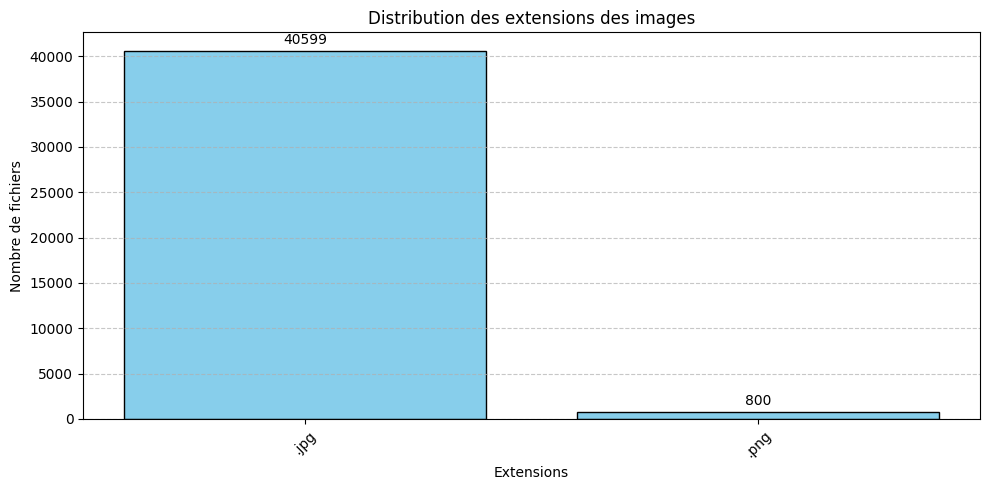

In [6]:
from collections import Counter
from pathlib import Path
import matplotlib.pyplot as plt

dossier = Path("./data/raw")

# 1. Comptage des extensions
extensions = Counter(
    f.suffix.lower()
    for f in dossier.rglob("*")
    if f.is_file() and f.suffix.lower() != ".ini"
)

# 2. Préparation des données pour le graphique
labels = [ext if ext else "[Sans ext]" for ext, _ in extensions.most_common()]
valeurs = [nombre for _, nombre in extensions.most_common()]

# 3. Création de l'histogramme
plt.figure(figsize=(10, 5))
bars = plt.bar(labels, valeurs, color="skyblue", edgecolor="black")

# Ajouter les valeurs au-dessus de chaque barre
plt.bar_label(bars, padding=3)

# Personnalisation des axes et du titre
plt.title("Distribution des extensions des images")
plt.xlabel("Extensions")
plt.ylabel("Nombre de fichiers")
plt.xticks(rotation=45)  # Incliner les labels si tu as beaucoup d'extensions
plt.grid(axis="y", linestyle="--", alpha=0.7)

# Ajuster l'affichage pour ne pas couper les labels
plt.tight_layout()
plt.show()

On y retrouve que deux extentions d'images jpg et png. On a majoritairement des jpg. Les deux formats ne seront pas compliqué à analyser

In [7]:
from collections import Counter
from pathlib import Path
from PIL import Image

dossier_racine = Path("./data/raw")

# Structure : { path_dossier: { 'exts': Counter(), 'canaux': Counter(), 'resolutions': [] } }
stats_dossiers = {}

for f in dossier_racine.rglob("*"):
    if f.is_file():
        ext = f.suffix.lower()

        # Filtrer .ini
        if ext in ".ini":
            continue

        dossier_parent = f.parent

        if dossier_parent not in stats_dossiers:
            stats_dossiers[dossier_parent] = {
                "exts": Counter(),
                "canaux": Counter(),
                "resolutions": [],
            }

        # 1. Comptage des extensions
        stats_dossiers[dossier_parent]["exts"][ext if ext else "[Sans ext]"] += 1

        # 2. Lecture des métadonnées images (résolution + canaux) via PIL
        try:
            with Image.open(f) as img:
                # Résolution (largeur, hauteur)
                stats_dossiers[dossier_parent]["resolutions"].append(img.size)

                # Canaux / Mode (ex: 'RGB' -> 3 canaux, 'RGBA' -> 4, 'L' -> 1)
                mode_image = img.mode
                nb_canaux = len(img.getbands())
                info_canal = f"{mode_image} ({nb_canaux})"

                stats_dossiers[dossier_parent]["canaux"][info_canal] += 1
        except Exception:
            # Fichier non-image ou corrompu
            pass

# Affichage des résultats
print("=" * 60)
print("ANALYSE COMPLÈTE DES DOSSIERS")
print("=" * 60)

for dossier, data in stats_dossiers.items():
    print(f"\nDossier : {dossier.name}")

    # 1. Extensions
    exts_str = ", ".join(
        [f"{ext}: {count}" for ext, count in data["exts"].items()]
    )
    print(f"  Types de fichiers : {exts_str}")

    # 2. Canaux
    if data["canaux"]:
        canaux_str = ", ".join(
            [f"{mode}: {count}" for mode, count in data["canaux"].items()]
        )
        print(f"  Canaux : {canaux_str}")

    # 3. Résolutions
    res_list = data["resolutions"]
    if res_list:
        res_min = min(res_list, key=lambda r: r[0] * r[1])
        res_max = max(res_list, key=lambda r: r[0] * r[1])

        larg_moy = sum(r[0] for r in res_list) / len(res_list)
        haut_moy = sum(r[1] for r in res_list) / len(res_list)

        print(f"  Résol. Min : {res_min[0]}x{res_min[1]} px")
        print(f"  Résol. Max : {res_max[0]}x{res_max[1]} px")
        print(f"  Résol. Moy. : {int(larg_moy)}x{int(haut_moy)} px ({len(res_list)} images)")
    else:
        print("Aucune image lisible trouvée")

print("=" * 60)

ANALYSE COMPLÈTE DES DOSSIERS

Dossier : Painting
  Types de fichiers : .jpg: 10000
  Canaux : RGB (3): 9907, L (1): 82, P (1): 5, CMYK (4): 1, RGBA (4): 5
  Résol. Min : 342x438 px
  Résol. Max : 6232x7880 px
  Résol. Moy. : 996x1023 px (10000 images)

Dossier : Photo
  Types de fichiers : .jpg: 9993
  Canaux : RGB (3): 9968, L (1): 25
  Résol. Min : 125x166 px
  Résol. Max : 640x640 px
  Résol. Moy. : 576x485 px (9993 images)

Dossier : Schematics
  Types de fichiers : .jpg: 10000
  Canaux : RGB (3): 9884, L (1): 116
  Résol. Min : 1x1 px
  Résol. Max : 7248x9894 px
  Résol. Moy. : 818x580 px (10000 images)

Dossier : Sketch
  Types de fichiers : .jpg: 606, .png: 800
  Canaux : RGB (3): 538, L (1): 868
  Résol. Min : 411x583 px
  Résol. Max : 1111x1111 px
  Résol. Moy. : 810x883 px (1406 images)

Dossier : Text
  Types de fichiers : .jpg: 10000
  Canaux : RGB (3): 10000
  Résol. Min : 360x540 px
  Résol. Max : 595x842 px
  Résol. Moy. : 567x789 px (10000 images)


Etape data processing image:
- Choisir la résolution de nos images (unique)
- Résoudre le probleme des images qui sont pas RGB
- Fusionné les fakes entre eux, et data augementation pour photo
- Divisé entre Train/Test/Valid en 75%/15%/10%

Voir si on peut faire:
- Supprimer les images avec des tailles trop aberrantes (trop petite ou trop grande)

Créer dossier prepocessing

In [10]:
import shutil
from pathlib import Path

# Définition des chemins
dossier_raw = Path("./data/raw")
dossier_preproc = Path("./data/preprocessing")

# Crée le dossier preprocessing s'il n'existe pas
dossier_preproc.mkdir(parents=True, exist_ok=True)

# Parcours uniquement les sous-dossiers directs de raw
for sous_dossier in dossier_raw.iterdir():
    if sous_dossier.is_dir():
        destination = dossier_preproc / sous_dossier.name

        # Copie complète du sous-dossier et de son contenu
        shutil.copytree(sous_dossier, destination, dirs_exist_ok=True)
        print(f"Copie terminée : {sous_dossier.name} -> {destination}")

Copie terminée : Painting -> data\preprocessing\Painting
Copie terminée : Photo -> data\preprocessing\Photo
Copie terminée : Schematics -> data\preprocessing\Schematics
Copie terminée : Sketch -> data\preprocessing\Sketch
Copie terminée : Text -> data\preprocessing\Text


## Cannaux

In [12]:
import os
from PIL import Image
from pathlib import Path

dossier_processing = Path("./data/preprocessing")
compteur_convertie = 0

for racine, dossiers, fichiers in os.walk(dossier_processing):
    for nom_fichier in fichiers:
        # Ignore les fichiers d'initialisation (.ini)
        if nom_fichier.lower().endswith('.ini'):
            continue
            
        chemin_image = os.path.join(racine, nom_fichier)
        
        try:
            with Image.open(chemin_image) as img:
                if img.mode == 'RGB':
                    continue
                img_convertie = img.convert('RGB')
            img_convertie.save(chemin_image)
            compteur_convertie =+ 1
        except Exception:
            pass
print(f"Image convertie en RGB {compteur_convertie}")

Image convertie en RGB 0


In [13]:
from collections import Counter
from pathlib import Path
from PIL import Image

dossier_racine = Path("./data/preprocessing")

# Structure : { path_dossier: { 'exts': Counter(), 'canaux': Counter(), 'resolutions': [] } }
stats_dossiers = {}

for f in dossier_racine.rglob("*"):
    if f.is_file():
        ext = f.suffix.lower()

        # Filtrer .ini
        if ext in ".ini":
            continue

        dossier_parent = f.parent

        if dossier_parent not in stats_dossiers:
            stats_dossiers[dossier_parent] = {
                "exts": Counter(),
                "canaux": Counter(),
                "resolutions": [],
            }

        # 1. Comptage des extensions
        stats_dossiers[dossier_parent]["exts"][ext if ext else "[Sans ext]"] += 1

        # 2. Lecture des métadonnées images (résolution + canaux) via PIL
        try:
            with Image.open(f) as img:
                # Résolution (largeur, hauteur)
                stats_dossiers[dossier_parent]["resolutions"].append(img.size)

                # Canaux / Mode (ex: 'RGB' -> 3 canaux, 'RGBA' -> 4, 'L' -> 1)
                mode_image = img.mode
                nb_canaux = len(img.getbands())
                info_canal = f"{mode_image} ({nb_canaux})"

                stats_dossiers[dossier_parent]["canaux"][info_canal] += 1
        except Exception:
            # Fichier non-image ou corrompu
            pass

# Affichage des résultats
print("=" * 60)
print("ANALYSE COMPLÈTE DES DOSSIERS")
print("=" * 60)

for dossier, data in stats_dossiers.items():
    print(f"\nDossier : {dossier.name}")

    # 1. Extensions
    exts_str = ", ".join(
        [f"{ext}: {count}" for ext, count in data["exts"].items()]
    )
    print(f"  Types de fichiers : {exts_str}")

    # 2. Canaux
    if data["canaux"]:
        canaux_str = ", ".join(
            [f"{mode}: {count}" for mode, count in data["canaux"].items()]
        )
        print(f"  Canaux : {canaux_str}")

    # 3. Résolutions
    res_list = data["resolutions"]
    if res_list:
        res_min = min(res_list, key=lambda r: r[0] * r[1])
        res_max = max(res_list, key=lambda r: r[0] * r[1])

        larg_moy = sum(r[0] for r in res_list) / len(res_list)
        haut_moy = sum(r[1] for r in res_list) / len(res_list)

        print(f"  Résol. Min : {res_min[0]}x{res_min[1]} px")
        print(f"  Résol. Max : {res_max[0]}x{res_max[1]} px")
        print(f"  Résol. Moy. : {int(larg_moy)}x{int(haut_moy)} px ({len(res_list)} images)")
    else:
        print("Aucune image lisible trouvée")

print("=" * 60)

ANALYSE COMPLÈTE DES DOSSIERS

Dossier : Painting
  Types de fichiers : .jpg: 10000
  Canaux : RGB (3): 10000
  Résol. Min : 342x438 px
  Résol. Max : 6232x7880 px
  Résol. Moy. : 996x1023 px (10000 images)

Dossier : Photo
  Types de fichiers : .jpg: 9993
  Canaux : RGB (3): 9993
  Résol. Min : 125x166 px
  Résol. Max : 640x640 px
  Résol. Moy. : 576x485 px (9993 images)

Dossier : Schematics
  Types de fichiers : .jpg: 10000
  Canaux : RGB (3): 10000
  Résol. Min : 1x1 px
  Résol. Max : 7248x9894 px
  Résol. Moy. : 818x580 px (10000 images)

Dossier : Sketch
  Types de fichiers : .jpg: 606, .png: 800
  Canaux : RGB (3): 1406
  Résol. Min : 411x583 px
  Résol. Max : 1111x1111 px
  Résol. Moy. : 810x883 px (1406 images)

Dossier : Text
  Types de fichiers : .jpg: 10000
  Canaux : RGB (3): 10000
  Résol. Min : 360x540 px
  Résol. Max : 595x842 px
  Résol. Moy. : 567x789 px (10000 images)
